In [1]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132
CUDA available: True
GPU: NVIDIA GB10


# 01 — Computer Vision Fundamentals

## Project 02: Deep Learning for Satellite Image Classification

### Overview

This notebook introduces the fundamentals of computer vision
using NumPy, Matplotlib, and PyTorch.

We will investigate how images are represented numerically,
how pixel data is organized, and how images are prepared for
deep-learning models.

### Learning Objectives

1. Understand digital image representation.
2. Explore grayscale and RGB images.
3. Manipulate image data with NumPy.
4. Convert image arrays into PyTorch tensors.
5. Understand image tensor dimensions.
6. Normalize pixel values.
7. Visualize individual RGB channels.
8. Transfer image tensors to the GPU.

### Hardware

NVIDIA DGX Spark

### Project Context

This notebook is part of a larger project investigating
satellite image classification using deep learning.

Subsequent notebooks will explore convolution operations,
CNN architectures, transfer learning, and model evaluation.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch

In [3]:
# create small image

grayscale_image = np.array([
    [0, 50, 100],
    [75, 125, 175],
    [150, 200, 255]
], dtype=np.uint8)

print("Image shape:", grayscale_image.shape)
print("Data type:", grayscale_image.dtype)
print("Pixel values:\n", grayscale_image)

Image shape: (3, 3)
Data type: uint8
Pixel values:
 [[  0  50 100]
 [ 75 125 175]
 [150 200 255]]


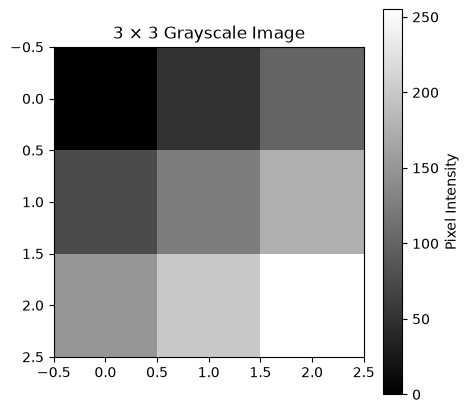

In [4]:
# visualize image

plt.figure(figsize=(5, 5))

plt.imshow(
    grayscale_image,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title("3 × 3 Grayscale Image")
plt.colorbar(label="Pixel Intensity")
plt.show()

In [5]:
# create color image

rgb_image = np.zeros((100, 100, 3), dtype=np.uint8)

# Red channel
rgb_image[:, :, 0] = 255

print("Image shape:", rgb_image.shape)
print("Data type:", rgb_image.dtype)

Image shape: (100, 100, 3)
Data type: uint8


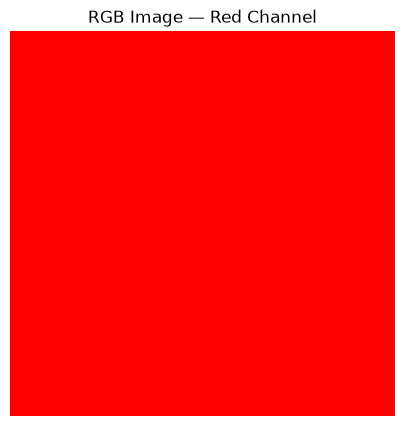

In [6]:
plt.figure(figsize=(5, 5))
plt.imshow(rgb_image)
plt.title("RGB Image — Red Channel")
plt.axis("off")
plt.show()

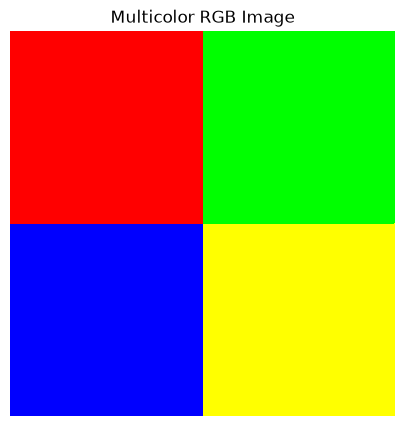

In [7]:
# multicolor image

image = np.zeros((100, 100, 3), dtype=np.uint8)

# Top-left: Red
image[:50, :50] = [255, 0, 0]

# Top-right: Green
image[:50, 50:] = [0, 255, 0]

# Bottom-left: Blue
image[50:, :50] = [0, 0, 255]

# Bottom-right: Yellow
image[50:, 50:] = [255, 255, 0]

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title("Multicolor RGB Image")
plt.axis("off")
plt.show()

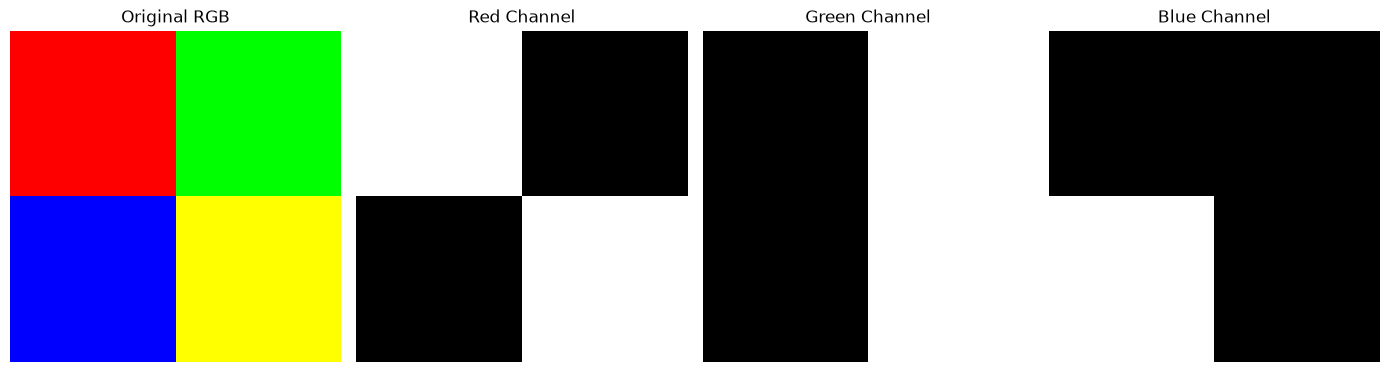

In [8]:
# extract rgb channels

red_channel = image[:, :, 0]
green_channel = image[:, :, 1]
blue_channel = image[:, :, 2]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

axes[0].imshow(image)
axes[0].set_title("Original RGB")

axes[1].imshow(red_channel, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Red Channel")

axes[2].imshow(green_channel, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Green Channel")

axes[3].imshow(blue_channel, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Blue Channel")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
# above

# The grayscale channel images represent the intensity of each color component.

# For example, the red channel displays white wherever red has an intensity of 255.

# It displays black wherever red has an intensity of zero.

# Notice that yellow contributes to both the red and green channels.

# This illustrates how an RGB image combines numerical information from three separate channels.